# Logistic Regression: Heart Failure Prediction

## Step 1: Import Libraries

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns, joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             roc_auc_score, roc_curve, ConfusionMatrixDisplay)

## Step 2: Load and Explore Data

In [2]:
df = pd.read_csv('heart.csv')
print(df.shape)
df.head()

(918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [4]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


## Step 3: Data Cleaning
In this dataset, 0 in `Cholesterol` and `RestingBP` means the value is missing.

In [5]:
print(df.isnull().sum())
df = df.drop_duplicates()

df = df[df['RestingBP'] > 0]                                   # remove invalid BP row
chol_median = df.loc[df['Cholesterol'] > 0, 'Cholesterol'].median()
df['Cholesterol'] = df['Cholesterol'].replace(0, chol_median)  # fill missing cholesterol
print(df.shape)

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64
(917, 12)


## Step 4: Target Distribution and Heatmap

1    507
0    410
Name: HeartDisease, dtype: int64


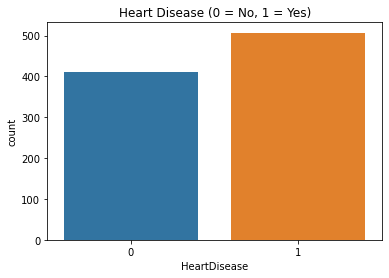

In [9]:
print(df['HeartDisease'].value_counts())
sns.countplot(x='HeartDisease', data=df)
plt.title('Heart Disease (0 = No, 1 = Yes)')
plt.show()


In [ ]:
num_cols = ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']
cat_cols = ['Sex', 'ChestPainType', 'ExerciseAngina', 'ST_Slope']

## Step 5: Split, Preprocess and Train

In [11]:
X = df[num_cols + cat_cols]
y = df['HeartDisease']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

preprocess = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

model = Pipeline([
    ('prep', preprocess),
    ('lr', LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Age', 'RestingBP',
                                                   'Cholesterol', 'FastingBS',
                                                   'MaxHR', 'Oldpeak']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Sex', 'ChestPainType',
                                                   'ExerciseAngina',
                                                   'ST_Slope'])])),
                ('lr', LogisticRegression(max_iter=1000))])

## Step 6: Model Evaluation

In [12]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy :", accuracy_score(y_test, y_pred))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob))
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=['Healthy','Heart Disease']))

Accuracy : 0.8804347826086957
ROC-AUC  : 0.943089430894309

Classification Report:
                precision    recall  f1-score   support

      Healthy       0.87      0.87      0.87        82
Heart Disease       0.89      0.89      0.89       102

     accuracy                           0.88       184
    macro avg       0.88      0.88      0.88       184
 weighted avg       0.88      0.88      0.88       184



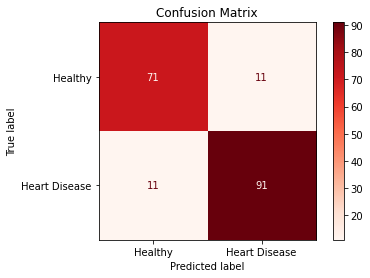

In [13]:
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=['Healthy','Heart Disease']).plot(cmap='Reds')
plt.title('Confusion Matrix')
plt.show()

## Step 7: Test One Prediction and Save the Model

In [15]:
sample = pd.DataFrame([{
    'Age': 58, 'RestingBP': 140, 'Cholesterol': 240, 'FastingBS': 1,
    'MaxHR': 120, 'Oldpeak': 2.0, 'Sex': 'M', 'ChestPainType': 'ASY',
    'ExerciseAngina': 'Y', 'ST_Slope': 'Flat'}])
print("Prediction:", "Heart Disease" if model.predict(sample)[0] == 1 else "Healthy")
print("Probability:", model.predict_proba(sample)[0][1])

joblib.dump(model, 'heart_model.pkl')
print("Model saved: heart_model.pkl")

Prediction: Heart Disease
Probability: 0.9877751050547668
Model saved: heart_model.pkl
